## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ashley Tibebe

**Date:** 10/08/2026

In [314]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

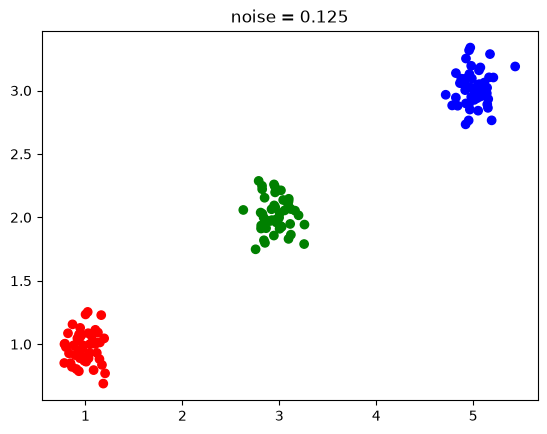

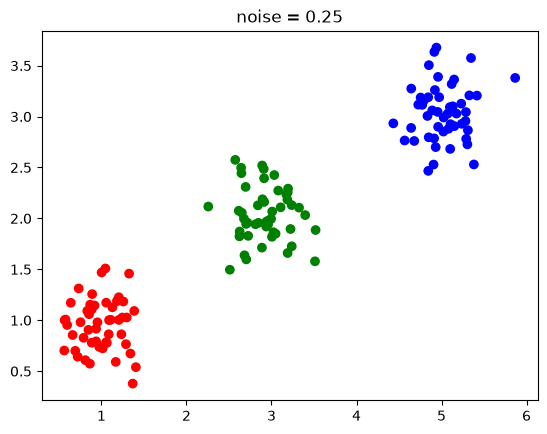

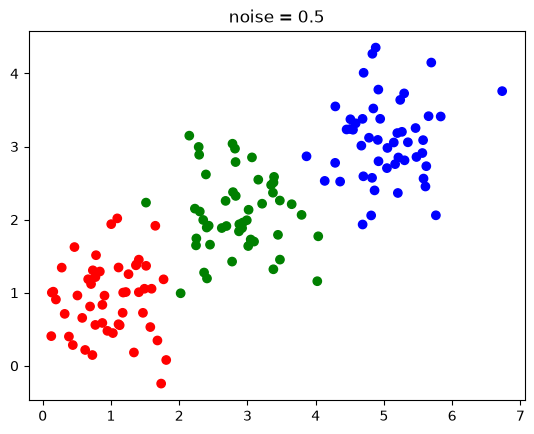

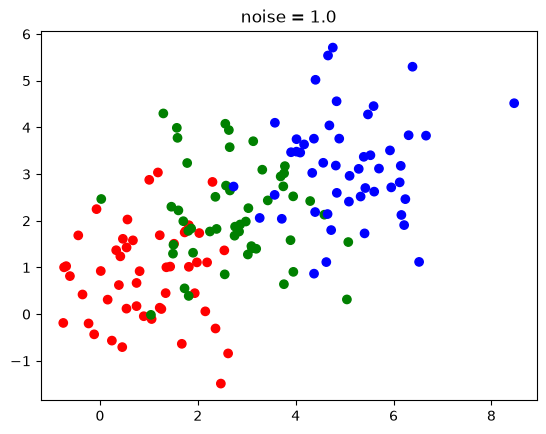

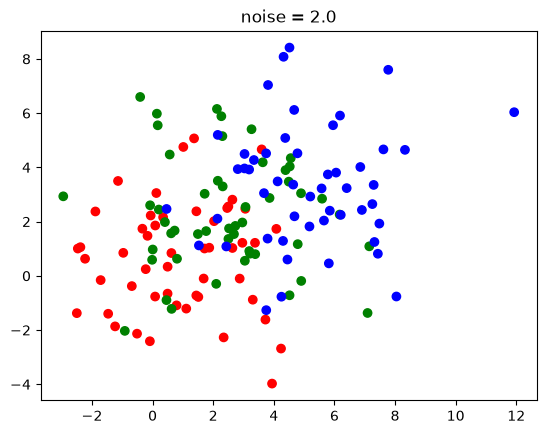

In [315]:
def scatter(df, title):
    colors = df['group'].map({'a': 'red', 'b': 'green', 'c': 'blue'})
    plt.scatter(df['x1'], df['x2'], c=colors)
    plt.title(title)
    plt.show()
scatter(df0_125, 'noise = 0.125')
scatter(df0_25, 'noise = 0.25')
scatter(df0_5, 'noise = 0.5')
scatter(df1_0, 'noise = 1.0')
scatter(df2_0, 'noise = 2.0')

As the noise increases, the visual distinctiveness of each cluseter decreases significantly. When noise = 0.125 (the smallest value here), each cluster is concentrated into distinct clusters. However, when looking at the scatterplot with the highest noise here (noise=2.0), each cluster blends together to the point where there are no distinct clusters.

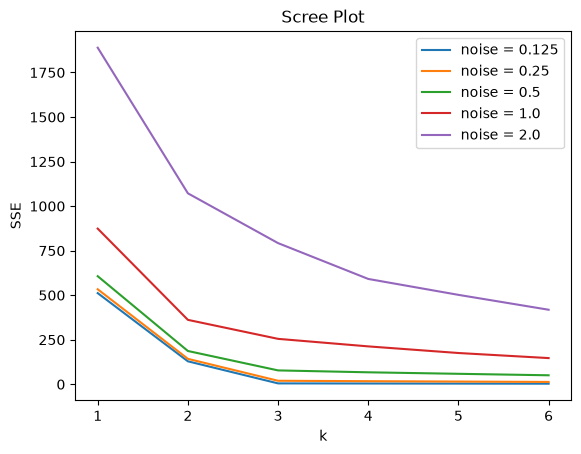

In [316]:
import seaborn as sns
from sklearn.cluster import KMeans
ks = np.arange(1, 7)

def getSSE(df):
    X = df[['x1', 'x2']]
    return [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]

sns.lineplot(x=ks, y=getSSE(df0_125), label="noise = 0.125")
sns.lineplot(x=ks, y=getSSE(df0_25), label="noise = 0.25")
sns.lineplot(x=ks, y=getSSE(df0_5), label="noise = 0.5")
sns.lineplot(x=ks, y=getSSE(df1_0), label="noise = 1.0")
ax = sns.lineplot(x=ks, y=getSSE(df2_0), label="noise = 2.0")
ax.set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

When comparing  the curves of each noise level with one another, I can see that as the level of noise increases, the scree plot shows a less defined/clear "elbow." Instead of it being a sharp point, it becomes more flattened out and more difficult to definitively identify. When there is less noise, the elbow is more distinct and selecting a k value is easier. This means that definitively selecting a k value from the curves with higher noise is impossible, which is understandable because the elbow method (from the scree plot) does not always give a clear choice of k.

The elbow in a scree plot is an indicator of how much each additional cluster (k-value) reduces the SSE (the error associated with each cluster and its center). In this case, when the k value (number of groups) finally reached the optimum k value that decreeased its error, we can see the "elbow" indicarted the sharp decline in SSE. In the example above, the optimum k value was k=3, at which we can see a sharp, defined "dip" or elbow, which signifies the k value that leads to thei sharp decrease in SSE. However, when we move away from this optimum k value the SSE barely drops, meaning additional clusters do not improve the error. 

In [317]:
#Q2
military = pd.read_csv('SIPRI Military Expenditure Database.csv')
military.head()

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,0,1988,Afghanistan,NaN,NaN,NaN,NaN
1,1,1989,Afghanistan,NaN,NaN,NaN,NaN
2,2,1990,Afghanistan,NaN,NaN,NaN,NaN
3,3,1991,Afghanistan,NaN,NaN,NaN,NaN
4,4,1992,Afghanistan,NaN,NaN,NaN,NaN


In [318]:
military = military[military["Year"] == 2020].dropna().reset_index(drop=True)
len(military)

148

In [319]:
print(military.dtypes)

index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


Because the correct number of countries resulted after removing all missing values and specifying for the year 2020 I decided to look at the data types to ensure they made sense for the particulr variable. After confirming this, I decided there was no additional cleaning of the variables required. 

[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

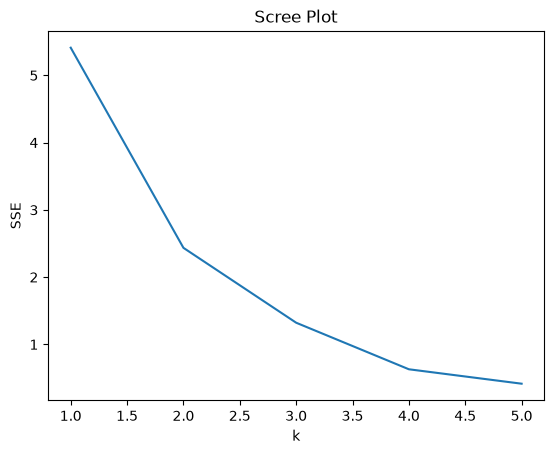

In [320]:
military['spend_norm'] = (military['Spending (2020 USD)'] - military['Spending (2020 USD)'].min()) / (military['Spending (2020 USD)'].max() - military['Spending (2020 USD)'].min())
military['percap_norm'] = (military['Spending per Capita'] - military['Spending per Capita'].min()) / (military['Spending per Capita'].max() - military['Spending per Capita'].min())

X = military[['spend_norm', 'percap_norm']]

ks = np.arange(1, 6)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

The "elbow" or optimal k value is 3.

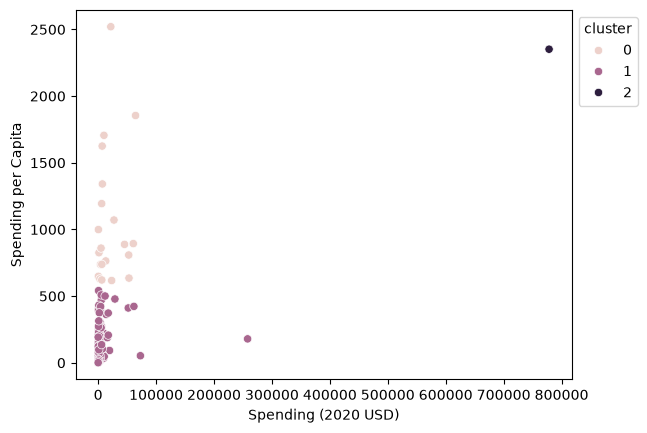

         index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0         21.0  2913.904762  1632.102874   236.0  1834.0  2922.0  4044.0   
1        126.0  2795.984127  1652.593453    32.0  1332.5  2769.0  4205.5   
2          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   

                  Year          ... spend_norm           percap_norm  \
            max  count    mean  ...        75%       max       count   
cluster                         ...                                    
0        5506.0   21.0  2020.0  ...   0.035063  0.082927        21.0   
1        5880.0  126.0  2020.0  ...   0.004133  0.331409       126.0   
2        5540.0    1.0  2020.0  ...   1.000000  1.000000         1.0   

                                                                               
             mean       std   

In [321]:
model = KMeans(n_clusters=3, n_init=10, random_state=0)
military['cluster'] = model.fit_predict(X)
ax = sns.scatterplot(data=military, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()
print(military.groupby('cluster').describe())

In [322]:
print(military[military['Country']== 'United States of America'])

     index  Year                   Country  Spending (2020 USD)  \
144   5540  2020  United States of America             778397.2   

     Percent of GDP  Percent of Government Spending  Spending per Capita  \
144        0.037179                        0.081976          2351.631858   

     spend_norm  percap_norm  cluster  
144         1.0     0.933024        2  


From the scree plot I can see that the optimum k value of "elbow" is at k=3, meaning three clusters is optimal for this data as the decrease in SSE after this point is negligible (the curve flattens out). From the cluster graph, I can see that the three clusters are drastically different is size and one of them has 126 countries, and another has just 21. The third cluster has just one country, which is the United States (in a cluster by itself). This means that the United States have a uniquily high spending per capita compared to other countries, earning it its own high cluster. One pattern in cluster membership I noticed is that the results are driven by outliers (especially in the case of the United States) because normalization is based on the US's extremely high spending, which causes the other countries to be clustered lower.

[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

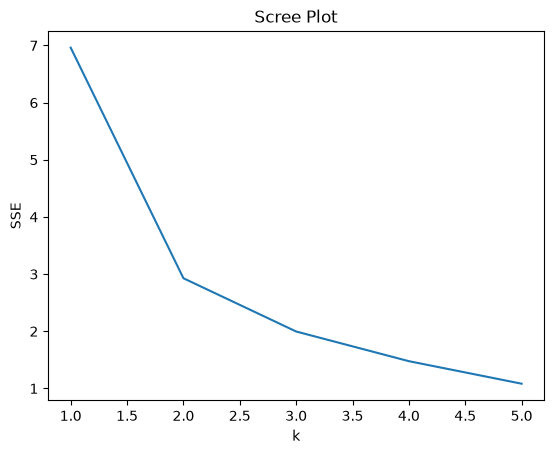

In [323]:
#Q2.3:
military['govspen_norm'] = (military['Percent of Government Spending'] - military['Percent of Government Spending'].min()) / (military['Percent of Government Spending'].max() - military['Percent of Government Spending'].min())
military['gdp_norm'] = (military['Percent of GDP'] - military['Percent of GDP'].min()) / (military['Percent of GDP'].max() - military['Percent of GDP'].min())

X = military[['govspen_norm', 'gdp_norm']]

ks = np.arange(1, 6)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")

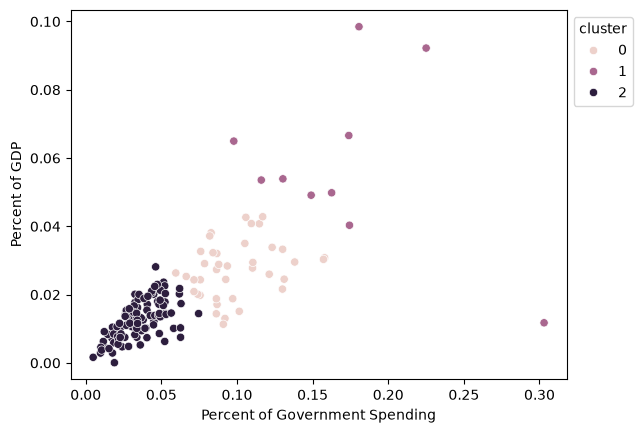

        index                                                           \
        count         mean          std    min     25%     50%     75%   
cluster                                                                  
0        39.0  2894.974359  1789.517893  338.0  1052.0  2854.0  4741.0   
1        10.0  2184.200000  1773.299110  100.0   329.5  2650.0  3763.5   
2        99.0  2871.515152  1590.144034   32.0  1647.0  2956.0  4197.0   

                 Year          ... govspen_norm           gdp_norm            \
            max count    mean  ...          75%       max    count      mean   
cluster                        ...                                             
0        5540.0  39.0  2020.0  ...     0.361373  0.513270     39.0  0.277982   
1        4486.0  10.0  2020.0  ...     0.584256  1.000000     10.0  0.589502   
2        5880.0  99.0  2020.0  ...     0.142575  0.233882     99.0  0.128133   

                                                                     
    

In [324]:
model = KMeans(n_clusters=3, n_init=10, random_state=0)
military['cluster'] = model.fit_predict(X)
ax = sns.scatterplot(data=military, x="Percent of Government Spending", y="Percent of GDP", hue="cluster")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()
print(military.groupby('cluster').describe())

From the scree plot, I can infer that a reasonable k value is k=3, which is the same as that in the previous part. In this cluster plot, I noticed that the clusters are ligned up along a diagonal line. This msuggests that the variables are positively correlated, which makes sense when looking at the variables. This cluster plot also has clear outliers (like the United States was on the plot prior).

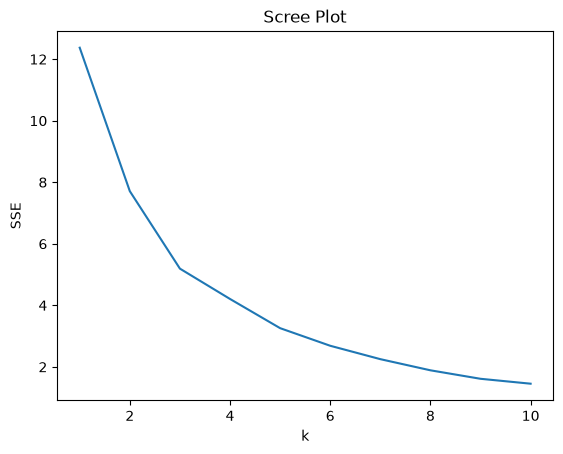

In [325]:
#Q2.4:
X = military[['spend_norm', 'percap_norm', 'govspen_norm', 'gdp_norm']]
ks = np.arange(1, 11)
SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

In [326]:
model = KMeans(n_clusters=5, n_init=10, random_state=0)
military['cluster4'] = model.fit_predict(X)

print(military.groupby('cluster4').describe())
print(military[military['Country'].str.contains('United States')])

         index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster4                                                                   
0         86.0  2841.744186  1630.948935    32.0  1536.5  2837.0  4205.5   
1          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   
2         30.0  2542.333333  1812.819719   100.0   763.0  2616.0  3729.5   
3         26.0  2851.384615  1592.766225   236.0  1732.0  2854.0  4214.0   
4          5.0  3738.000000   935.154533  2582.0  2922.0  4044.0  4486.0   

                  Year          ... govspen_norm           gdp_norm            \
             max count    mean  ...          75%       max    count      mean   
cluster4                        ...                                             
0         5880.0  86.0  2020.0  ...     0.161369  0.324036     86.0  0.126272   
1         5540.0   1.0  2020.0  ...     0.258544  0.258544      1.0

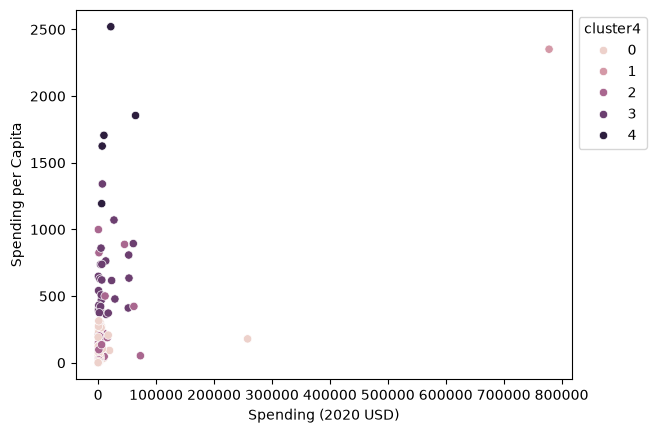

In [327]:
ax = sns.scatterplot(data=military, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster4")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()

Based on the scree plot, the optimal number of clusters for the combined features is 5. From the cluster plot I can see that the United States still seems to be an outlier it its own cluster. The cluster plot also seems very similar to that in part 1 of this analysis (the first cluster plot made on this Q).

Yes, the k-MC algorithm has helped first by selecting the optimum k value for the number of clusters and also by identifying patterns of extreme outliers thorugh the cluster plots. This was mostly the case for the United States, which had high spendings. One limitation is that some scree plots have soft elbows and thus identifying the k value can be tricky. 

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [328]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]